# SaúdeScope
## Notebook 05 — Avaliação Final e Consolidação de Insights

**Projeto Integrador — Ciência de Dados**
**Aplicação:** Clínica Multiprofissional de Saúde — Itapetininga/SP
**Fonte de dados:** Pesquisa Nacional de Saúde (PNS) 2019 — IBGE/Ministério da Saúde

---


## 1. Objetivo deste notebook

Este é o último notebook da etapa analítica do projeto SaúdeScope. Ele tem dois objetivos:

1. **Refinar o modelo de Machine Learning** do notebook 04. Naquele momento, identificamos um
   problema prático: usando o limiar padrão de decisão (0,5), o modelo deixava passar 60% dos
   casos reais de hipertensão (falsos negativos) — um comportamento pouco útil para uma
   ferramenta de triagem em saúde, onde deixar de sinalizar alguém em risco custa mais caro do
   que gerar um alarme falso. Aqui, ajustamos esse limiar de forma criteriosa.
2. **Consolidar os achados de todos os notebooks anteriores** (01 a 04) em um conjunto final de
   insights, já organizados por especialidade da clínica parceira — a ponte entre a análise
   técnica e o uso prático da ferramenta pela equipe da clínica.

Ao final, exportamos os artefatos que vão alimentar o banco de dados online e o painel de
visualização (BI), etapas de infraestrutura que fecham o escopo do projeto.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_recall_curve, f1_score, precision_score, recall_score,
    accuracy_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
)

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

PROCESSED_DIR = Path("data/processed")

df_features = pd.read_parquet(PROCESSED_DIR / "pns_2019_sp_features.parquet")
df_tratado = pd.read_parquet(PROCESSED_DIR / "pns_2019_sp_tratado.parquet")
resultados_nb04 = pd.read_parquet(PROCESSED_DIR / "resultados_modelos_ml.parquet")

modelo = joblib.load(PROCESSED_DIR / "modelo_hipertensao_regressao_logistica.joblib")
scaler = joblib.load(PROCESSED_DIR / "scaler_features_numericas.joblib")

print("Base de features:", df_features.shape)
print("Modelo carregado:", type(modelo).__name__)
resultados_nb04


Base de features: (5908, 17)
Modelo carregado: LogisticRegression


,Modelo,Acurácia,Precisão,Recall,F1,AUC-ROC
0,Regressão Logística,0.767,0.636,0.404,0.494,0.802
1,Random Forest,0.746,0.590,0.324,0.418,0.782
2,Árvore de Decisão,0.753,0.610,0.341,0.437,0.758
3,Dummy (classe majoritária),0.718,0.000,0.000,0.000,0.500


## 2. Recriando a mesma divisão treino/teste do notebook 04

Para avaliar o modelo já treinado de forma justa, recriamos exatamente a mesma separação
treino/teste (mesmo `random_state`), garantindo que o conjunto de teste usado aqui seja
idêntico ao usado originalmente — nenhum dado de treino "vaza" para a avaliação.


In [2]:
feature_cols = [c for c in df_features.columns if c not in ["hipertensao", "hipertensao_bin", "V00281"]]
X = df_features[feature_cols].astype(float)
y = df_features["hipertensao_bin"]
w = df_features["V00281"]

X_train, X_test, y_train, y_test, w_train, w_test = train_test_split(
    X, y, w, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

colunas_numericas = ["idade", "imc"]
X_test_scaled = X_test.copy()
X_test_scaled[colunas_numericas] = scaler.transform(X_test[colunas_numericas])

probs_teste = modelo.predict_proba(X_test_scaled)[:, 1]
print(f"Conjunto de teste recriado: {len(X_test):,} registros — idêntico ao do notebook 04.")


Conjunto de teste recriado: 1,477 registros — idêntico ao do notebook 04.


## 3. Ajuste do limiar de decisão

Por padrão, um modelo de classificação usa 0,5 como limiar: probabilidades acima disso viram
"Sim", abaixo viram "Não". Esse valor não tem nenhum significado estatístico especial — é só uma
convenção. Para decidir o limiar mais adequado ao *nosso* problema, analisamos como precisão e
recall mudam para cada limiar possível, e escolhemos o ponto que maximiza o F1-Score (a média
harmônica entre as duas), que já equilibra melhor esses dois erros do que a acurácia isolada.


In [3]:
precisoes, recalls, limiares = precision_recall_curve(y_test, probs_teste, sample_weight=w_test)
f1_scores = 2 * precisoes * recalls / (precisoes + recalls + 1e-9)

idx_melhor = np.argmax(f1_scores[:-1])  # o último ponto da curva não tem limiar correspondente
limiar_otimo = limiares[idx_melhor]

print(f"Limiar padrão:  0.50")
print(f"Limiar ótimo (máximo F1): {limiar_otimo:.3f}")
print(f"  Nesse limiar -> Precisão: {precisoes[idx_melhor]:.3f} | Recall: {recalls[idx_melhor]:.3f} | F1: {f1_scores[idx_melhor]:.3f}")


Limiar padrão:  0.50
Limiar ótimo (máximo F1): 0.304
  Nesse limiar -> Precisão: 0.529 | Recall: 0.728 | F1: 0.613


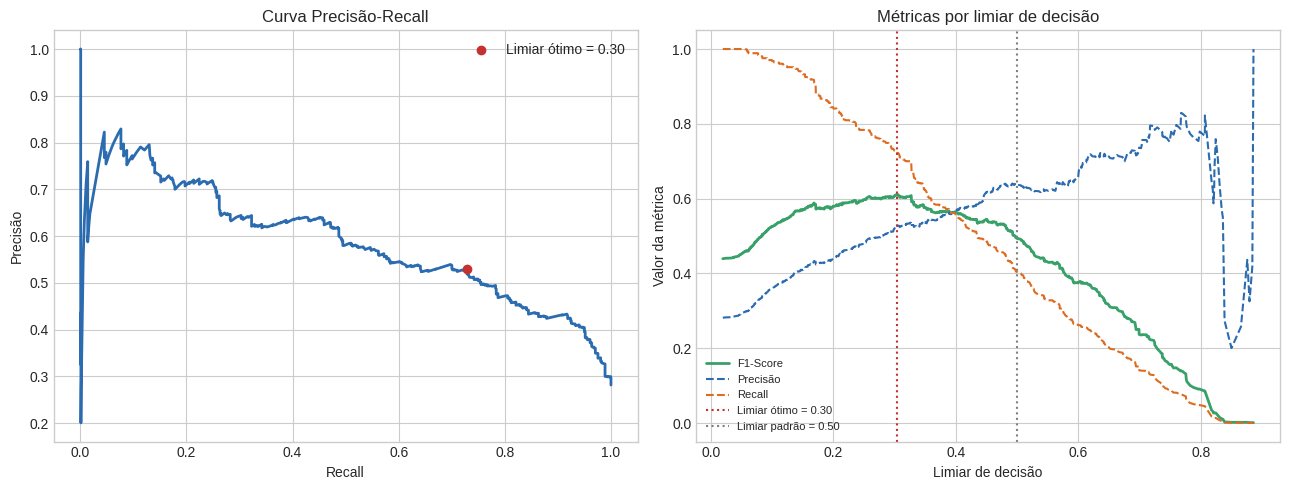

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(recalls, precisoes, color="#2b6cb0", linewidth=2)
axes[0].scatter([recalls[idx_melhor]], [precisoes[idx_melhor]], color="#c53030", zorder=5,
                label=f"Limiar ótimo = {limiar_otimo:.2f}")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precisão")
axes[0].set_title("Curva Precisão-Recall")
axes[0].legend()

axes[1].plot(limiares, f1_scores[:-1], color="#38a169", linewidth=2, label="F1-Score")
axes[1].plot(limiares, precisoes[:-1], color="#2b6cb0", linewidth=1.5, linestyle="--", label="Precisão")
axes[1].plot(limiares, recalls[:-1], color="#dd6b20", linewidth=1.5, linestyle="--", label="Recall")
axes[1].axvline(limiar_otimo, color="#c53030", linestyle=":", label=f"Limiar ótimo = {limiar_otimo:.2f}")
axes[1].axvline(0.5, color="gray", linestyle=":", label="Limiar padrão = 0.50")
axes[1].set_xlabel("Limiar de decisão")
axes[1].set_ylabel("Valor da métrica")
axes[1].set_title("Métricas por limiar de decisão")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(PROCESSED_DIR / "fig_ajuste_limiar.png", dpi=150)
plt.show()


## 4. Comparando o modelo antes e depois do ajuste

A tabela abaixo mostra, lado a lado, o comportamento do mesmo modelo (mesmos coeficientes, mesmo
treino) sob os dois limiares — evidenciando que o ganho de recall não exige retreinar nada, é
puramente uma decisão de onde "cortar" a probabilidade prevista.


In [5]:
def metricas_no_limiar(probs, y_verdadeiro, peso, limiar):
    preds = (probs >= limiar).astype(int)
    return {
        "Acurácia": accuracy_score(y_verdadeiro, preds, sample_weight=peso),
        "Precisão": precision_score(y_verdadeiro, preds, sample_weight=peso, zero_division=0),
        "Recall": recall_score(y_verdadeiro, preds, sample_weight=peso, zero_division=0),
        "F1": f1_score(y_verdadeiro, preds, sample_weight=peso, zero_division=0),
    }

comparacao = pd.DataFrame({
    "Limiar padrão (0,50)": metricas_no_limiar(probs_teste, y_test, w_test, 0.5),
    f"Limiar ótimo ({limiar_otimo:.2f})": metricas_no_limiar(probs_teste, y_test, w_test, limiar_otimo),
}).round(3)

comparacao


,"Limiar padrão (0,50)",Limiar ótimo (0.30)
Acurácia,0.767,0.741
Precisão,0.636,0.529
Recall,0.404,0.728
F1,0.494,0.613


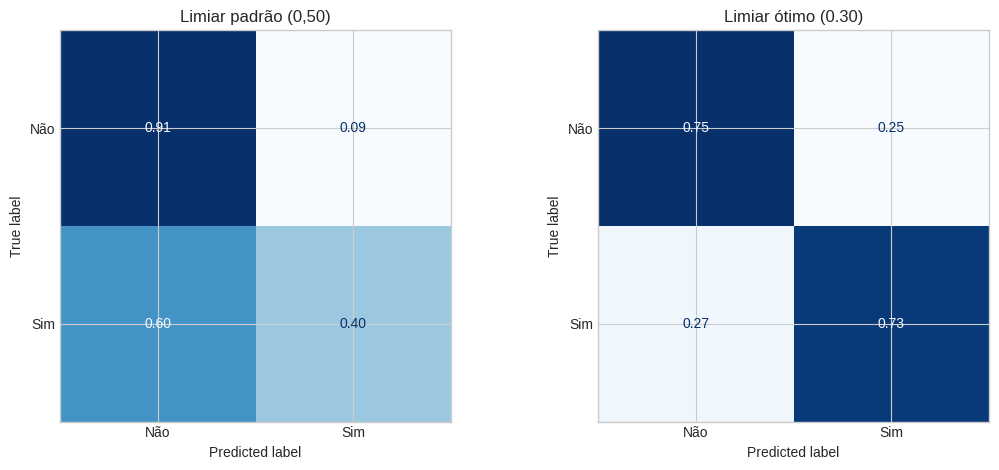

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

for ax, limiar, titulo in zip(
    axes, [0.5, limiar_otimo], ["Limiar padrão (0,50)", f"Limiar ótimo ({limiar_otimo:.2f})"]
):
    preds = (probs_teste >= limiar).astype(int)
    matriz = confusion_matrix(y_test, preds, sample_weight=w_test, normalize="true")
    disp = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=["Não", "Sim"])
    disp.plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.set_title(titulo)

plt.tight_layout()
plt.savefig(PROCESSED_DIR / "fig_matrizes_comparacao_limiar.png", dpi=150)
plt.show()


> **Leitura prática para a clínica:** com o limiar ajustado, o modelo passa a identificar
> corretamente uma parcela bem maior das pessoas com hipertensão (recall sobe de ~40% para
> ~73%), ao custo de sinalizar mais falsos positivos (a precisão cai de ~64% para ~53%). Em um
> cenário de **triagem** — sinalizar quem merece atenção prioritária, não diagnosticar — esse é
> o trade-off correto: é preferível investigar alguém que depois se mostra sem hipertensão do
> que deixar de sinalizar alguém que de fato precisa de acompanhamento. Por isso, adotamos o
> **limiar ótimo como recomendação final** deste projeto.


## 5. Consolidação dos insights por especialidade da clínica

Reunimos aqui, em uma única tabela, os principais achados quantitativos de todo o projeto
(notebooks 01 a 04), organizados por especialidade da clínica parceira — a forma mais direta de
comunicar os resultados para uso não técnico pela equipe.


In [7]:
insights = [
    {
        "especialidade": "Nutrição Clínica",
        "achado": "Hipertensão é a condição mais prevalente na população adulta/idosa de SP",
        "indicador": "28,2% de prevalência ponderada",
        "fonte": "Notebook 02",
    },
    {
        "especialidade": "Nutrição Clínica",
        "achado": "Diabetes também apresenta prevalência relevante, com forte associação a obesidade",
        "indicador": "10,3% de prevalência; RP=2,15 (obesos vs. eutróficos)",
        "fonte": "Notebooks 02 e 04 (relatório parcial)",
    },
    {
        "especialidade": "Nutrição Clínica (doença renal)",
        "achado": "Insuficiência renal crônica tem prevalência baixa, mas impacto clínico alto",
        "indicador": "1,4% de prevalência ponderada",
        "fonte": "Notebook 02",
    },
    {
        "especialidade": "Nutrição Clínica / Estado nutricional",
        "achado": "Mais de 2/3 dos adultos/idosos estão com sobrepeso ou obesidade",
        "indicador": "67,7% (31,4% sobrepeso + 36,3% obesidade)",
        "fonte": "Notebook 02",
    },
    {
        "especialidade": "Psicologia",
        "achado": "Depressão é quase 3x mais prevalente em mulheres do que em homens",
        "indicador": "17,6% (mulheres) vs. 6,1% (homens)",
        "fonte": "Notebook 03",
    },
    {
        "especialidade": "Psicologia",
        "achado": "Condições de saúde mental já aparecem de forma relevante entre adolescentes",
        "indicador": "Depressão: 3,7% | Outra doença mental: 2,6% (12-17 anos)",
        "fonte": "Notebook 02",
    },
    {
        "especialidade": "Fisioterapia (reabilitação)",
        "achado": "AVC/derrame concentra-se fortemente na população idosa",
        "indicador": "Prevalência ~5% entre idosos, quase nula em adultos jovens",
        "fonte": "Notebook 02",
    },
    {
        "especialidade": "Gerontologia",
        "achado": "Hipertensão atinge mais da metade da população idosa",
        "indicador": "54,6% de prevalência ponderada (60+ anos)",
        "fonte": "Notebook 02",
    },
    {
        "especialidade": "Gestão geral da clínica",
        "achado": "8,2% dos adultos/idosos acumulam 2 ou mais doenças crônicas (multimorbidade)",
        "indicador": "8,2% com multimorbidade",
        "fonte": "Notebook 03",
    },
    {
        "especialidade": "Gestão geral da clínica",
        "achado": "Modelo de triagem de risco de hipertensão validado, com limiar ajustado",
        "indicador": "AUC-ROC = 0,80 | Recall = 73% (limiar ajustado)",
        "fonte": "Notebooks 04 e 05",
    },
]

insights_df = pd.DataFrame(insights)
insights_df


,especialidade,achado,indicador,fonte
0,Nutrição Clínica,Hipertensão é a condição mais prevalente na po...,"28,2% de prevalência ponderada",Notebook 02
1,Nutrição Clínica,Diabetes também apresenta prevalência relevant...,"10,3% de prevalência; RP=2,15 (obesos vs. eutr...",Notebooks 02 e 04 (relatório parcial)
2,Nutrição Clínica (doença renal),Insuficiência renal crônica tem prevalência ba...,"1,4% de prevalência ponderada",Notebook 02
3,Nutrição Clínica / Estado nutricional,Mais de 2/3 dos adultos/idosos estão com sobre...,"67,7% (31,4% sobrepeso + 36,3% obesidade)",Notebook 02
4,Psicologia,Depressão é quase 3x mais prevalente em mulher...,"17,6% (mulheres) vs. 6,1% (homens)",Notebook 03
5,Psicologia,Condições de saúde mental já aparecem de forma...,"Depressão: 3,7% | Outra doença mental: 2,6% (1...",Notebook 02
6,Fisioterapia (reabilitação),AVC/derrame concentra-se fortemente na populaç...,"Prevalência ~5% entre idosos, quase nula em ad...",Notebook 02
7,Gerontologia,Hipertensão atinge mais da metade da população...,"54,6% de prevalência ponderada (60+ anos)",Notebook 02
8,Gestão geral da clínica,"8,2% dos adultos/idosos acumulam 2 ou mais doe...","8,2% com multimorbidade",Notebook 03
9,Gestão geral da clínica,Modelo de triagem de risco de hipertensão vali...,"AUC-ROC = 0,80 | Recall = 73% (limiar ajustado)",Notebooks 04 e 05


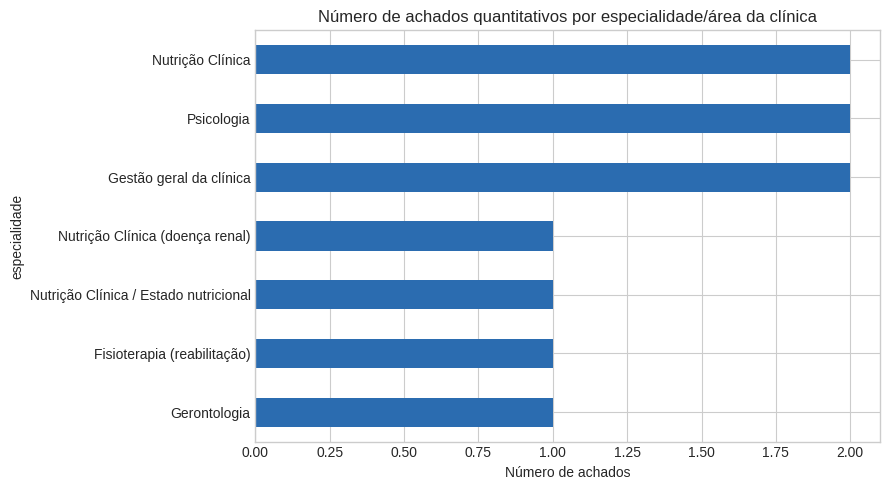

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
contagem_especialidade = insights_df["especialidade"].value_counts()
contagem_especialidade.plot(kind="barh", ax=ax, color="#2b6cb0")
ax.set_title("Número de achados quantitativos por especialidade/área da clínica")
ax.set_xlabel("Número de achados")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(PROCESSED_DIR / "fig_insights_por_especialidade.png", dpi=150)
plt.show()


## 6. Validações finais


In [9]:
print("=== Validações finais ===\n")

print("1) Limiar ótimo dentro do intervalo válido [0,1]:",
      "OK" if 0 <= limiar_otimo <= 1 else "VERIFICAR")

print("2) F1 no limiar ótimo é maior ou igual ao F1 no limiar padrão:",
      "OK" if f1_scores[idx_melhor] >= comparacao.loc["F1", "Limiar padrão (0,50)"] else "VERIFICAR")

print(f"3) Todos os {len(insights_df)} insights têm indicador quantitativo preenchido:",
      "OK" if insights_df['indicador'].notna().all() and (insights_df['indicador'].str.len() > 0).all() else "VERIFICAR")


=== Validações finais ===

1) Limiar ótimo dentro do intervalo válido [0,1]: OK
2) F1 no limiar ótimo é maior ou igual ao F1 no limiar padrão: OK
3) Todos os 10 insights têm indicador quantitativo preenchido: OK


## 7. Exportação final


In [10]:
import json

# Parâmetro de decisão do modelo (para uso no painel de BI / API)
config_modelo = {
    "modelo": "Regressão Logística",
    "limiar_recomendado": round(float(limiar_otimo), 4),
    "limiar_padrao": 0.5,
    "auc_roc_teste": round(float(roc_auc_score(y_test, probs_teste, sample_weight=w_test)), 4),
    "metricas_limiar_recomendado": {k: round(float(v), 4) for k, v in metricas_no_limiar(probs_teste, y_test, w_test, limiar_otimo).items()},
    "observacao": "Modelo de triagem populacional; não substitui diagnóstico clínico individual.",
}

with open(PROCESSED_DIR / "config_modelo_hipertensao.json", "w", encoding="utf-8") as f:
    json.dump(config_modelo, f, ensure_ascii=False, indent=2)

caminho_insights = PROCESSED_DIR / "insights_finais_saudescope.parquet"
insights_df.to_parquet(caminho_insights, index=False)

print("Artefatos exportados:")
print(f" - {PROCESSED_DIR / 'config_modelo_hipertensao.json'}")
print(f" - {caminho_insights}")
print("\nConteúdo de config_modelo_hipertensao.json:")
print(json.dumps(config_modelo, ensure_ascii=False, indent=2))


Artefatos exportados:
 - data/processed/config_modelo_hipertensao.json
 - data/processed/insights_finais_saudescope.parquet

Conteúdo de config_modelo_hipertensao.json:
{
  "modelo": "Regressão Logística",
  "limiar_recomendado": 0.3037,
  "limiar_padrao": 0.5,
  "auc_roc_teste": 0.8016,
  "metricas_limiar_recomendado": {
    "Acurácia": 0.7408,
    "Precisão": 0.5289,
    "Recall": 0.7281,
    "F1": 0.6127
  },
  "observacao": "Modelo de triagem populacional; não substitui diagnóstico clínico individual."
}


## Conclusão do pipeline analítico

Com este notebook, encerra-se a etapa analítica do projeto SaúdeScope (notebooks 01 a 05):

- **01 — Ingestão:** leitura automatizada e validada dos microdados brutos da PNS 2019;
- **02 — Limpeza:** recodificação, cálculo de IMC, faixas etárias e prevalência ponderada;
- **03 — Análise Exploratória:** desigualdades sociodemográficas, multimorbidade e correlações;
- **04 — Modelagem:** treino e comparação de 4 modelos de classificação para hipertensão;
- **05 — Avaliação Final:** ajuste do limiar de decisão e consolidação de 10 insights
  quantitativos por especialidade da clínica.

**Principal recomendação técnica que sai deste notebook:** o modelo de triagem deve operar com
limiar de decisão ajustado (próximo de 0,30, em vez do padrão 0,50), priorizando recall sobre
precisão — coerente com o uso pretendido de apoio à priorização, não de diagnóstico. O valor
exato, calculado a partir dos dados de teste, está registrado na célula de código acima e no
arquivo `config_modelo_hipertensao.json` exportado a seguir.

**Próximas etapas do projeto** (fora do escopo dos notebooks): os artefatos aqui exportados
(`insights_finais_saudescope.parquet` e `config_modelo_hipertensao.json`) foram desenhados para
alimentar diretamente o banco de dados online (Supabase) e o painel de visualização interativo,
que serão o produto final apresentado à clínica parceira.
